In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [ ]:
!pip -q install torch torchvision matplotlib pandas pillow

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader, Subset

import torchvision
from torchvision import datasets, transforms
from torchvision.models import (
    resnet50,
    ResNet50_Weights,
    vit_b_16,
    ViT_B_16_Weights
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


## fixed the random seed so that the experiment is more reproducible

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Seed:", SEED)

Seed: 42


## Loading models


In [ ]:
# -------------------------
# ResNet50
# -------------------------
resnet_weights = ResNet50_Weights.DEFAULT
resnet_model = resnet50(weights=resnet_weights)
resnet_model = resnet_model.to(device)
resnet_model.eval()

# -------------------------
# ViT-B/16
# -------------------------
vit_weights = ViT_B_16_Weights.DEFAULT
vit_model = vit_b_16(weights=vit_weights)
vit_model = vit_model.to(device)
vit_model.eval()

print("ResNet50 loaded")
print("ViT-B/16 loaded")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 62.8MB/s]


Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:02<00:00, 167MB/s]


ResNet50 loaded
ViT-B/16 loaded


In [ ]:
# model info
print("ResNet50 parameters:",
      sum(p.numel() for p in resnet_model.parameters()))

print("ViT-B/16 parameters:",
      sum(p.numel() for p in vit_model.parameters()))

ResNet50 parameters: 25557032
ViT-B/16 parameters: 86567656


In [ ]:
# preprocessing

resnet_transform = resnet_weights.transforms()
vit_transform = vit_weights.transforms()

print(resnet_transform)
print(vit_transform)

ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


## DATASET

In [ ]:
from torchvision import datasets

raw_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True
)

print("Total test images:", len(raw_dataset))
print("Classes:", raw_dataset.classes)

100%|██████████| 170M/170M [24:11<00:00, 117kB/s]


Total test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [ ]:
# all cat images
CAT_CLASS_ID = raw_dataset.class_to_idx["cat"]

cat_indices = [
    i for i, label in enumerate(raw_dataset.targets)
    if label == CAT_CLASS_ID
]

print("Number of cat images:", len(cat_indices))
print("Cat class ID:", CAT_CLASS_ID)

Number of cat images: 1000
Cat class ID: 3


In [ ]:
import torch
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import Dataset, DataLoader

import numpy as np
import matplotlib.pyplot as plt

In [ ]:
class CIFARCatDataset(torch.utils.data.Dataset):

    def __init__(self, base_dataset, indices, transform):
        self.base_dataset = base_dataset
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        real_idx = self.indices[idx]

        image, label = self.base_dataset[real_idx]

        image = self.transform(image)

        return image, label, real_idx

In [ ]:
from torchvision import transforms

resnet_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


vit_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:
# dataset for the models

resnet_cat_dataset = CIFARCatDataset(
    raw_dataset,
    cat_indices,
    resnet_transform
)

vit_cat_dataset = CIFARCatDataset(
    raw_dataset,
    cat_indices,
    vit_transform
)

print("ResNet dataset:", len(resnet_cat_dataset))
print("ViT dataset:", len(vit_cat_dataset))

ResNet dataset: 1000
ViT dataset: 1000


In [ ]:
from torchvision import models

resnet_weights = models.ResNet50_Weights.DEFAULT

In [ ]:
# getiing imagenet class names -
imagenet_categories = resnet_weights.meta["categories"]

print("Number of ImageNet classes:", len(imagenet_categories))

for i, name in enumerate(imagenet_categories):
    if "cat" in name.lower():
        print(i, name)


# collecting them

CAT_IMAGENET_IDS = [
    i for i, name in enumerate(imagenet_categories)
    if "cat" in name.lower()
]

CAT_IMAGENET_NAMES = [
    imagenet_categories[i]
    for i in CAT_IMAGENET_IDS
]

print("Cat-related ImageNet classes:")
for i, name in zip(CAT_IMAGENET_IDS, CAT_IMAGENET_NAMES):
    print(i, name)

Number of ImageNet classes: 1000
143 oystercatcher
282 tiger cat
283 Persian cat
284 Siamese cat
285 Egyptian cat
358 polecat
383 Madagascar cat
484 catamaran
Cat-related ImageNet classes:
143 oystercatcher
282 tiger cat
283 Persian cat
284 Siamese cat
285 Egyptian cat
358 polecat
383 Madagascar cat
484 catamaran


# Prediction


In [ ]:
@torch.no_grad()
def predict(model, images, categories):
    """
    Returns top-1 ImageNet prediction and confidence.
    """

    outputs = model(images)

    probabilities = torch.softmax(outputs, dim=1)

    confidence, predicted = probabilities.max(dim=1)

    results = []

    for i in range(len(images)):
        class_id = predicted[i].item()
        conf = confidence[i].item()

        results.append({
            "class_id": class_id,
            "class_name": categories[class_id],
            "confidence": conf
        })

    return results

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using:", device)

Using: cuda


In [ ]:
from torchvision import models

resnet_weights = models.ResNet50_Weights.DEFAULT

resnet_model = models.resnet50(weights=resnet_weights)

resnet_model = resnet_model.to(device)
resnet_model.eval()

print("ResNet50 loaded successfully")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 189MB/s]


ResNet50 loaded successfully


In [ ]:
# Testing

image, label, original_index = resnet_cat_dataset[0]

image_batch = image.unsqueeze(0).to(device)

result = predict(
    resnet_model,
    image_batch,
    imagenet_categories
)[0]

print("CIFAR label: cat")
print("Model prediction:", result["class_name"])
print("Confidence:", f"{result['confidence']:.4f}")

# visualise

def show_tensor_image(tensor, title="Image"):
    image = tensor.detach().cpu()

    # Undo ImageNet normalization
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    image = image * std + mean
    image = image.clamp(0, 1)

    plt.figure(figsize=(5, 5))
    plt.imshow(image.permute(1, 2, 0))
    plt.axis("off")
    plt.title(title)
    plt.show()




CIFAR label: cat
Model prediction: can opener
Confidence: 0.0396


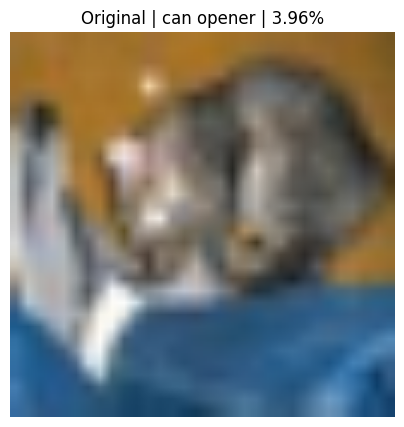

In [ ]:
show_tensor_image(
    image,
    f"Original | {result['class_name']} | {result['confidence']:.2%}"
)

# FGSM

In [ ]:
def fgsm_attack(model, images, labels, epsilon):
    images = images.clone().detach().to(device)
    labels = labels.clone().detach().to(device)

    images.requires_grad = True

    outputs = model(images)

    loss = F.cross_entropy(outputs, labels)

    model.zero_grad()
    loss.backward()

    gradient = images.grad.detach()

    perturbation = epsilon * gradient.sign()

    adversarial_images = images + perturbation

    # ImageNet normalization parameters
    mean = torch.tensor(
        [0.485, 0.456, 0.406],
        device=device
    ).view(1, 3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225],
        device=device
    ).view(1, 3, 1, 1)

    # Valid normalized range corresponding to pixel values [0, 1]
    lower = (0.0 - mean) / std
    upper = (1.0 - mean) / std

    adversarial_images = torch.max(
        torch.min(adversarial_images, upper),
        lower
    )

    return adversarial_images.detach(), perturbation.detach()

In [ ]:
# untarget attack to move image away from its curr class

image, _, _ = resnet_cat_dataset[0]

image = image.unsqueeze(0).to(device)

# Get current model prediction
with torch.no_grad():
    output = resnet_model(image)
    original_label = output.argmax(dim=1)

print(
    "Original prediction:",
    imagenet_categories[original_label.item()]
)

Original prediction: can opener


In [ ]:
import torch.nn.functional as F

In [ ]:
epsilon = 0.02

adv_image, perturbation = fgsm_attack(
    resnet_model,
    image,
    original_label,
    epsilon
)

adv_result = predict(
    resnet_model,
    adv_image,
    imagenet_categories
)[0]

print("Original:",
      imagenet_categories[original_label.item()])

print("After FGSM:",
      adv_result["class_name"])

print("Confidence:",
      f"{adv_result['confidence']:.4f}")

Original: can opener
After FGSM: fox squirrel
Confidence: 0.0505


## Visualizing all

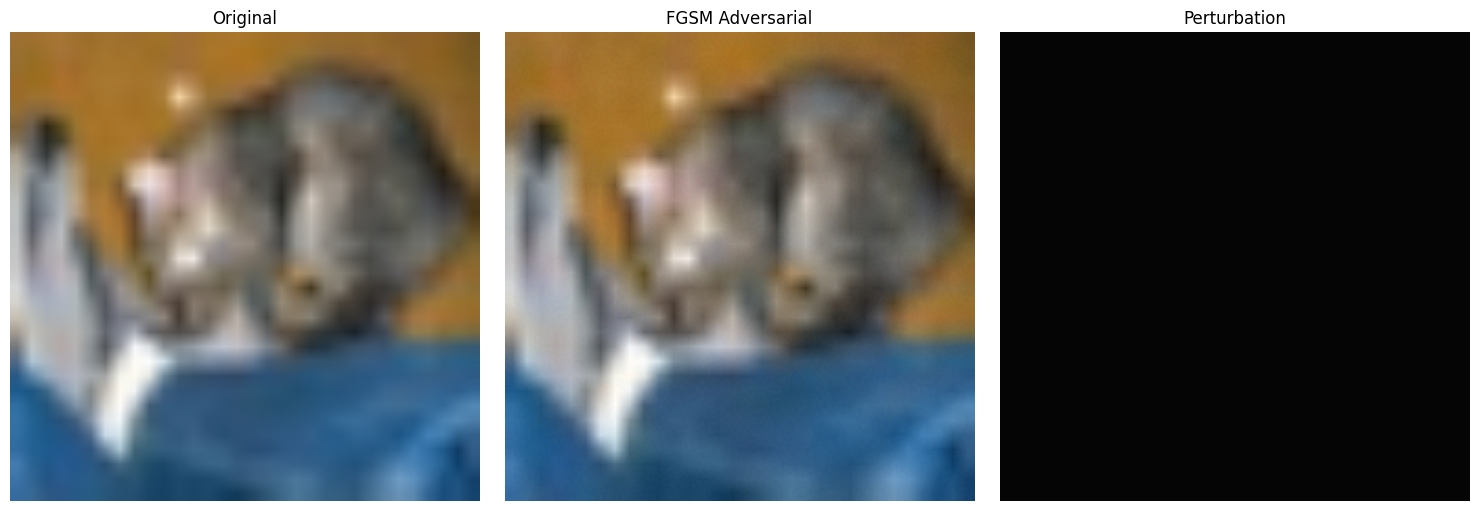

In [ ]:
def denormalize(tensor):
    mean = torch.tensor(
        [0.485, 0.456, 0.406],
        device=tensor.device
    ).view(1, 3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225],
        device=tensor.device
    ).view(1, 3, 1, 1)

    return (tensor * std + mean).clamp(0, 1)


original_display = denormalize(image)[0].cpu()
adv_display = denormalize(adv_image)[0].cpu()

perturb_display = perturbation[0].abs().cpu()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(original_display.permute(1, 2, 0))
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(adv_display.permute(1, 2, 0))
axes[1].set_title("FGSM Adversarial")
axes[1].axis("off")

axes[2].imshow(perturb_display.permute(1, 2, 0))
axes[2].set_title("Perturbation")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("fgsm_example.png", dpi=200)
plt.show()

# **PGD**

In [ ]:
def pgd_attack(
    model,
    images,
    labels,
    epsilon=0.02,
    alpha=0.005,
    num_steps=10,
    random_start=True
):
    """
    Projected Gradient Descent attack under an L-infinity constraint.
    """

    original_images = images.clone().detach().to(device)
    labels = labels.clone().detach().to(device)

    if random_start:
        delta = torch.empty_like(original_images).uniform_(
            -epsilon,
            epsilon
        )

        adv_images = original_images + delta

    else:
        adv_images = original_images.clone()

    # ImageNet normalized valid range
    mean = torch.tensor(
        [0.485, 0.456, 0.406],
        device=device
    ).view(1, 3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225],
        device=device
    ).view(1, 3, 1, 1)

    lower = (0.0 - mean) / std
    upper = (1.0 - mean) / std

    for _ in range(num_steps):

        adv_images.requires_grad = True

        outputs = model(adv_images)

        loss = F.cross_entropy(outputs, labels)

        model.zero_grad()

        loss.backward()

        gradient = adv_images.grad.detach()

        # Gradient ascent on loss
        adv_images = adv_images.detach() + alpha * gradient.sign()

        # Project back into L-infinity epsilon ball
        delta = torch.clamp(
            adv_images - original_images,
            min=-epsilon,
            max=epsilon
        )

        adv_images = original_images + delta

        # Keep valid image values
        adv_images = torch.max(
            torch.min(adv_images, upper),
            lower
        )

    return adv_images.detach()

In [ ]:
# Applying pgd on the image

epsilon = 0.02
alpha = 0.005
steps = 10

pgd_image = pgd_attack(
    resnet_model,
    image,
    original_label,
    epsilon=epsilon,
    alpha=alpha,
    num_steps=steps,
    random_start=True
)

pgd_result = predict(
    resnet_model,
    pgd_image,
    imagenet_categories
)[0]

print("Original:",
      imagenet_categories[original_label.item()])

print("After PGD:",
      pgd_result["class_name"])

print("Confidence:",
      f"{pgd_result['confidence']:.4f}")

Original: can opener
After PGD: grey fox
Confidence: 0.8557


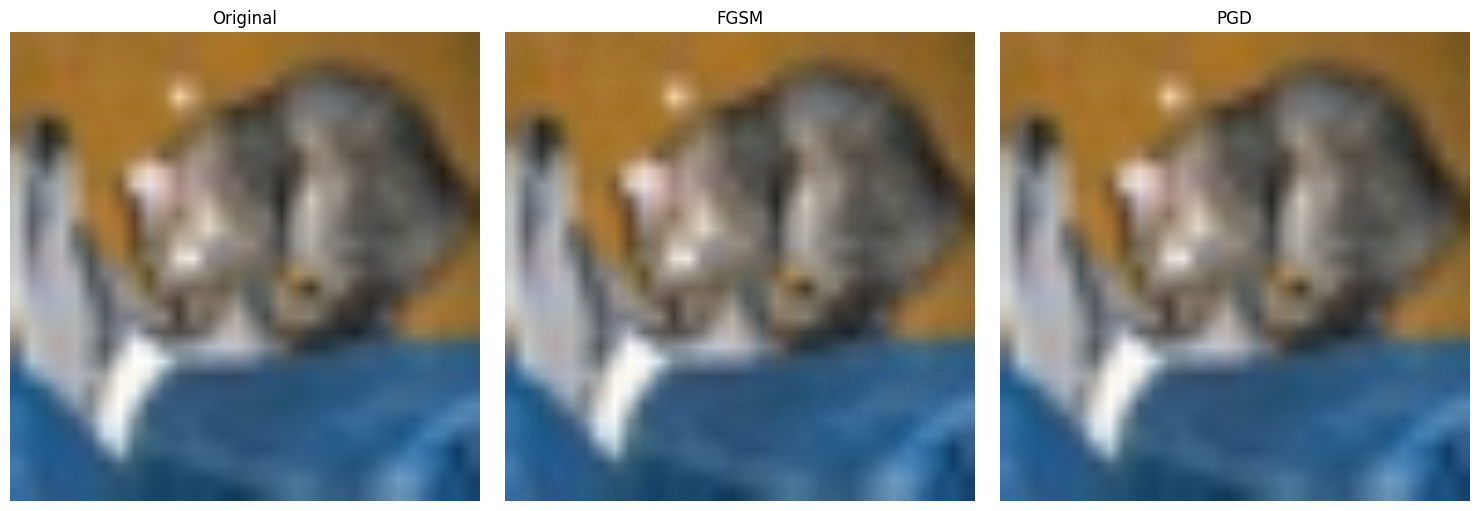

In [ ]:
# visualising pgd

pgd_display = denormalize(pgd_image)[0].cpu()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(original_display.permute(1, 2, 0))
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(adv_display.permute(1, 2, 0))
axes[1].set_title("FGSM")
axes[1].axis("off")

axes[2].imshow(pgd_display.permute(1, 2, 0))
axes[2].set_title("PGD")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("fgsm_vs_pgd.png", dpi=200)
plt.show()

# **Increasing no. of images and checking accuracy**

In [ ]:
# SELECTING
NUM_IMAGES = 100

experiment_indices = cat_indices[:NUM_IMAGES]

print("Images used:", len(experiment_indices))

# CREATING batch loader
resnet_experiment_dataset = CIFARCatDataset(
    raw_dataset,
    experiment_indices,
    resnet_transform
)

vit_experiment_dataset = CIFARCatDataset(
    raw_dataset,
    experiment_indices,
    vit_transform
)

resnet_loader = DataLoader(
    resnet_experiment_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

vit_loader = DataLoader(
    vit_experiment_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

Images used: 100


# Evaluation Function

In [ ]:
def evaluate_model(
    model,
    loader,
    categories,
    cat_imagenet_ids,
    epsilon=0.02,
    alpha=0.005,
    pgd_steps=10,
    max_batches=None
):

    model.eval()

    cat_imagenet_ids = set(cat_imagenet_ids)

    clean_correct = 0
    fgsm_correct = 0
    pgd_correct = 0

    total = 0

    for batch_idx, (images, _, _) in enumerate(loader):

        if max_batches is not None and batch_idx >= max_batches:
            break

        images = images.to(device)

        batch_size = images.size(0)
        total += batch_size

        # -------------------------
        # Clean predictions
        # -------------------------

        with torch.no_grad():
            clean_outputs = model(images)

        clean_predictions = clean_outputs.argmax(dim=1)

        clean_correct += sum(
            pred.item() in cat_imagenet_ids
            for pred in clean_predictions
        )

        # -------------------------
        # Use clean prediction
        # as attack label
        # -------------------------

        attack_labels = clean_predictions.detach()

        # -------------------------
        # FGSM
        # -------------------------

        fgsm_images, _ = fgsm_attack(
            model,
            images,
            attack_labels,
            epsilon
        )

        with torch.no_grad():
            fgsm_outputs = model(fgsm_images)

        fgsm_predictions = fgsm_outputs.argmax(dim=1)

        fgsm_correct += sum(
            pred.item() in cat_imagenet_ids
            for pred in fgsm_predictions
        )

        # -------------------------
        # PGD
        # -------------------------

        pgd_images = pgd_attack(
            model,
            images,
            attack_labels,
            epsilon=epsilon,
            alpha=alpha,
            num_steps=pgd_steps,
            random_start=True
        )

        with torch.no_grad():
            pgd_outputs = model(pgd_images)

        pgd_predictions = pgd_outputs.argmax(dim=1)

        pgd_correct += sum(
            pred.item() in cat_imagenet_ids
            for pred in pgd_predictions
        )

        print(
            f"Processed {total} images...",
            end="\r"
        )

    results = {
        "Clean Accuracy": clean_correct / total,
        "FGSM Accuracy": fgsm_correct / total,
        "PGD Accuracy": pgd_correct / total,
        "Images": total
    }

    return results

# Res net experiment

In [ ]:
resnet_results = evaluate_model(
    resnet_model,
    resnet_loader,
    imagenet_categories,
    CAT_IMAGENET_IDS,
    epsilon=0.02,
    alpha=0.005,
    pgd_steps=10
)

print("\nResNet50 Results")
print("----------------")
for key, value in resnet_results.items():
    if "Accuracy" in key:
        print(key, f"{value:.2%}")
    else:
        print(key, value)

Processed 100 images...
ResNet50 Results
----------------
Clean Accuracy 16.00%
FGSM Accuracy 12.00%
PGD Accuracy 6.00%
Images 100


# ViT experiment

In [ ]:
from torchvision import models

vit_weights = models.ViT_B_16_Weights.DEFAULT

vit_model = models.vit_b_16(weights=vit_weights)

vit_model = vit_model.to(device)
vit_model.eval()

print("ViT-B/16 loaded successfully")

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:02<00:00, 116MB/s] 


ViT-B/16 loaded successfully


In [ ]:
vit_results = evaluate_model(
    vit_model,
    vit_loader,
    imagenet_categories,
    CAT_IMAGENET_IDS,
    epsilon=0.02,
    alpha=0.005,
    pgd_steps=10
)

print("\nViT-B/16 Results")
print("----------------")
for key, value in vit_results.items():
    if "Accuracy" in key:
        print(key, f"{value:.2%}")
    else:
        print(key, value)

Processed 100 images...
ViT-B/16 Results
----------------
Clean Accuracy 27.00%
FGSM Accuracy 17.00%
PGD Accuracy 19.00%
Images 100


# **Benchmark table**

In [ ]:
import pandas as pd
comparison = pd.DataFrame({
    "Model": [
        "ResNet50",
        "ViT-B/16"
    ],
    "Clean Accuracy": [
        resnet_results["Clean Accuracy"],
        vit_results["Clean Accuracy"]
    ],
    "FGSM Accuracy": [
        resnet_results["FGSM Accuracy"],
        vit_results["FGSM Accuracy"]
    ],
    "PGD Accuracy": [
        resnet_results["PGD Accuracy"],
        vit_results["PGD Accuracy"]
    ],
    "Images": [
        resnet_results["Images"],
        vit_results["Images"]
    ]
})

comparison

,Model,Clean Accuracy,FGSM Accuracy,PGD Accuracy,Images
0,ResNet50,0.16,0.12,0.06,100
1,ViT-B/16,0.27,0.17,0.19,100


In [ ]:
# saving results

comparison.to_csv(
    "resnet_vs_vit_adversarial_results.csv",
    index=False
)

print("Saved: resnet_vs_vit_adversarial_results.csv")

Saved: resnet_vs_vit_adversarial_results.csv


# **Benchmark Graph**

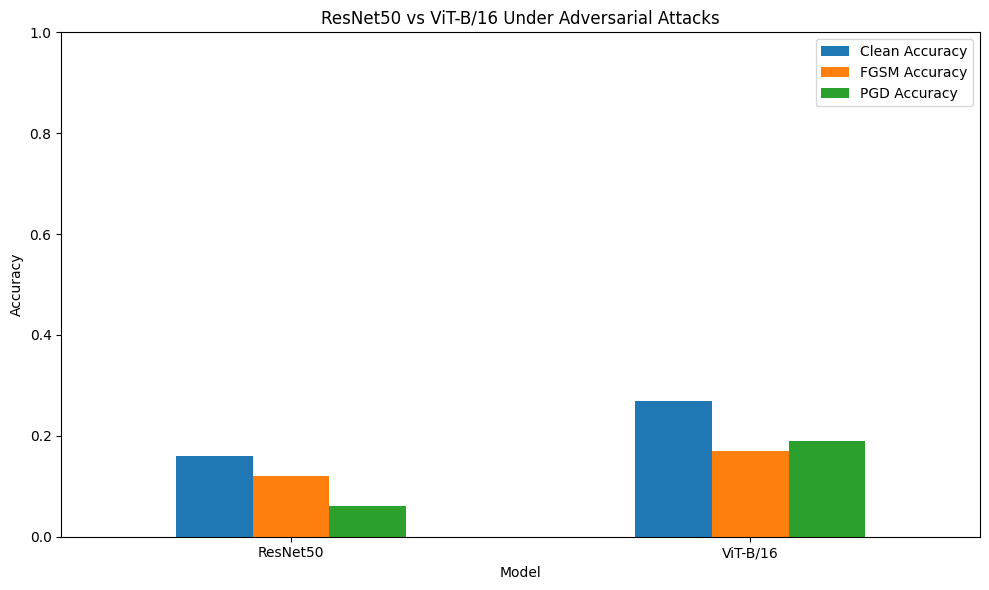

In [ ]:
plot_data = comparison.set_index("Model")[
    [
        "Clean Accuracy",
        "FGSM Accuracy",
        "PGD Accuracy"
    ]
]

plot_data.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title("ResNet50 vs ViT-B/16 Under Adversarial Attacks")
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()

plt.savefig(
    "resnet_vs_vit_comparison.png",
    dpi=200
)

plt.show()

## Multiple epsilon values

In [ ]:
EPSILONS = [
    0.0,
    0.005,
    0.01,
    0.02,
    0.04
]

In [ ]:
def evaluate_attack_strengths(
    model,
    loader,
    categories,
    cat_imagenet_ids,
    epsilons,
    pgd_alpha=0.005,
    pgd_steps=10,
    max_batches=None
):

    results = []

    cat_ids = set(cat_imagenet_ids)

    for epsilon in epsilons:

        print(f"\nTesting epsilon = {epsilon}")

        clean_correct = 0
        fgsm_correct = 0
        pgd_correct = 0
        total = 0

        for batch_idx, (images, _, _) in enumerate(loader):

            if max_batches is not None and batch_idx >= max_batches:
                break

            images = images.to(device)

            total += images.size(0)

            # Clean
            with torch.no_grad():
                outputs = model(images)

            clean_pred = outputs.argmax(dim=1)

            clean_correct += sum(
                p.item() in cat_ids
                for p in clean_pred
            )

            # Attack using current prediction
            attack_labels = clean_pred.detach()

            # FGSM
            if epsilon == 0:
                fgsm_images = images.clone()
            else:
                fgsm_images, _ = fgsm_attack(
                    model,
                    images,
                    attack_labels,
                    epsilon
                )

            with torch.no_grad():
                fgsm_pred = model(
                    fgsm_images
                ).argmax(dim=1)

            fgsm_correct += sum(
                p.item() in cat_ids
                for p in fgsm_pred
            )

            # PGD
            if epsilon == 0:
                pgd_images = images.clone()
            else:
                alpha = min(pgd_alpha, epsilon)

                pgd_images = pgd_attack(
                    model,
                    images,
                    attack_labels,
                    epsilon=epsilon,
                    alpha=alpha,
                    num_steps=pgd_steps,
                    random_start=True
                )

            with torch.no_grad():
                pgd_pred = model(
                    pgd_images
                ).argmax(dim=1)

            pgd_correct += sum(
                p.item() in cat_ids
                for p in pgd_pred
            )

        results.append({
            "epsilon": epsilon,
            "clean_accuracy": clean_correct / total,
            "fgsm_accuracy": fgsm_correct / total,
            "pgd_accuracy": pgd_correct / total,
            "images": total
        })

    return pd.DataFrame(results)

## For ResNet

In [ ]:
resnet_epsilon_results = evaluate_attack_strengths(
    resnet_model,
    resnet_loader,
    imagenet_categories,
    CAT_IMAGENET_IDS,
    EPSILONS,
    pgd_alpha=0.005,
    pgd_steps=10
)

resnet_epsilon_results


Testing epsilon = 0.0

Testing epsilon = 0.005

Testing epsilon = 0.01

Testing epsilon = 0.02

Testing epsilon = 0.04


,epsilon,clean_accuracy,fgsm_accuracy,pgd_accuracy,images
0,0.000,0.16,0.16,0.16,100
1,0.005,0.16,0.21,0.12,100
2,0.010,0.16,0.16,0.13,100
3,0.020,0.16,0.12,0.06,100
4,0.040,0.16,0.11,0.08,100


In [ ]:
# save
resnet_epsilon_results.to_csv(
    "resnet_epsilon_results.csv",
    index=False
)

## For ViT

In [ ]:
vit_epsilon_results = evaluate_attack_strengths(
    vit_model,
    vit_loader,
    imagenet_categories,
    CAT_IMAGENET_IDS,
    EPSILONS,
    pgd_alpha=0.005,
    pgd_steps=10
)

vit_epsilon_results


Testing epsilon = 0.0

Testing epsilon = 0.005

Testing epsilon = 0.01

Testing epsilon = 0.02

Testing epsilon = 0.04


,epsilon,clean_accuracy,fgsm_accuracy,pgd_accuracy,images
0,0.000,0.27,0.27,0.27,100
1,0.005,0.27,0.25,0.16,100
2,0.010,0.27,0.23,0.19,100
3,0.020,0.27,0.17,0.19,100
4,0.040,0.27,0.14,0.18,100


In [ ]:
# Save
vit_epsilon_results.to_csv(
    "vit_epsilon_results.csv",
    index=False
)

# **Ploting attack strength**

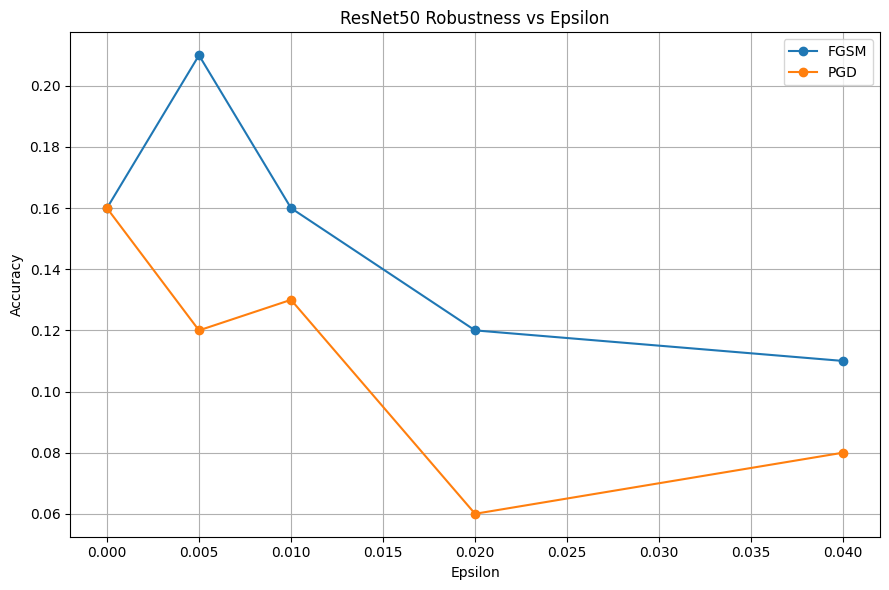

In [ ]:
# ResNet
plt.figure(figsize=(9, 6))

plt.plot(
    resnet_epsilon_results["epsilon"],
    resnet_epsilon_results["fgsm_accuracy"],
    marker="o",
    label="FGSM"
)

plt.plot(
    resnet_epsilon_results["epsilon"],
    resnet_epsilon_results["pgd_accuracy"],
    marker="o",
    label="PGD"
)

plt.xlabel("Epsilon")
plt.ylabel("Accuracy")
plt.title("ResNet50 Robustness vs Epsilon")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "resnet_robustness_vs_epsilon.png",
    dpi=200
)

plt.show()

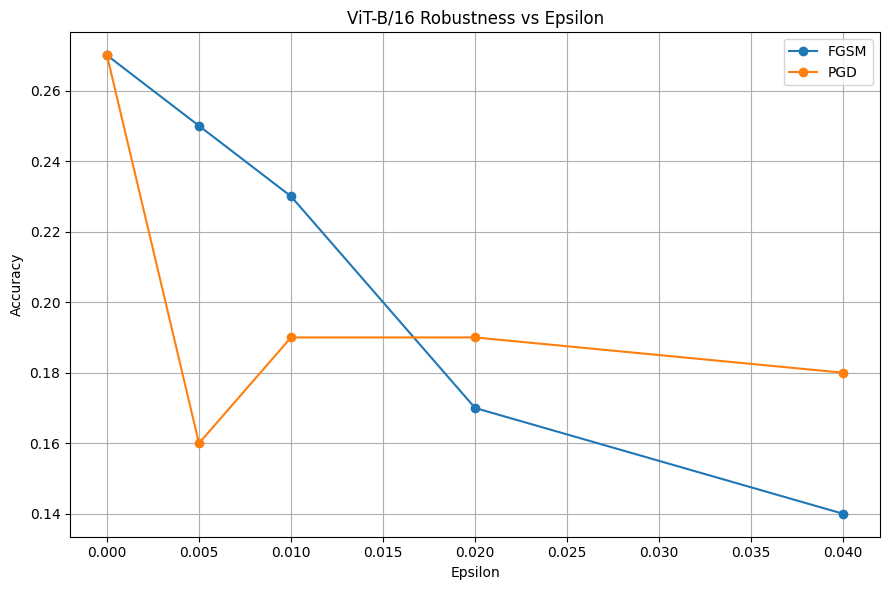

In [ ]:
# ViT
plt.figure(figsize=(9, 6))

plt.plot(
    vit_epsilon_results["epsilon"],
    vit_epsilon_results["fgsm_accuracy"],
    marker="o",
    label="FGSM"
)

plt.plot(
    vit_epsilon_results["epsilon"],
    vit_epsilon_results["pgd_accuracy"],
    marker="o",
    label="PGD"
)

plt.xlabel("Epsilon")
plt.ylabel("Accuracy")
plt.title("ViT-B/16 Robustness vs Epsilon")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "vit_robustness_vs_epsilon.png",
    dpi=200
)

plt.show()

In [ ]:
IMAGE_COUNTS = [10, 50, 100, 500]



---



In [ ]:
# ============================================================
# LOAD CIFAR-10 TEST DATASET
# ============================================================

from torchvision import datasets

raw_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True
)

print("CIFAR-10 loaded")
print("Total test images:", len(raw_dataset))
print("Classes:", raw_dataset.classes)

100%|██████████| 170M/170M [06:39<00:00, 427kB/s]


CIFAR-10 loaded
Total test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [ ]:
# ============================================================
# ALL CIFAR-10 CLASSES: PRETRAINED MODEL EVALUATION
# ============================================================

# CIFAR-10 class names
CIFAR_CLASSES = raw_dataset.classes

print("CIFAR-10 Classes:")
for i, name in enumerate(CIFAR_CLASSES):
    print(i, name)


# ------------------------------------------------------------
# Map each CIFAR-10 class to relevant ImageNet categories
# ------------------------------------------------------------

def find_imagenet_classes(keywords):
    """
    Find ImageNet class IDs whose names contain any keyword.
    """
    ids = []

    for i, name in enumerate(imagenet_categories):
        name_lower = name.lower()

        for keyword in keywords:
            if keyword.lower() in name_lower:
                ids.append(i)
                break

    return ids


CIFAR_TO_IMAGENET_KEYWORDS = {

    "airplane": [
        "airliner",
        "warplane",
        "space shuttle"
    ],

    "automobile": [
        "sports car",
        "racer",
        "car",
        "limousine"
    ],

    "bird": [
        "bird"
    ],

    "cat": [
        "cat"
    ],

    "deer": [
        "deer",
        "elk",
        "moose"
    ],

    "dog": [
        "dog",
        "terrier",
        "retriever",
        "hound",
        "spaniel",
        "shepherd",
        "poodle",
        "bulldog",
        "mastiff",
        "husky",
        "malamute",
        "collie",
        "chihuahua",
        "beagle",
        "boxer",
        "dalmatian",
        "doberman",
        "pinscher",
        "rottweiler",
        "schnauzer",
        "samoyed",
        "pug"
    ],

    "frog": [
        "frog"
    ],

    "horse": [
        "horse",
        "zebra"
    ],

    "ship": [
        "ship",
        "boat",
        "liner",
        "vessel"
    ],

    "truck": [
        "truck",
        "pickup",
        "lorry",
        "trailer"
    ]
}


# Create ImageNet ID mapping
CIFAR_IMAGENET_IDS = {}

for cifar_class, keywords in CIFAR_TO_IMAGENET_KEYWORDS.items():

    ids = find_imagenet_classes(keywords)

    CIFAR_IMAGENET_IDS[cifar_class] = ids

    print("\n", cifar_class)
    print("Number of ImageNet classes:", len(ids))

    # Show first few matching ImageNet names
    print([
        imagenet_categories[i]
        for i in ids[:15]
    ])


# ------------------------------------------------------------
# Create datasets for ALL CIFAR images
# ------------------------------------------------------------

class CIFARAllDataset(torch.utils.data.Dataset):

    def __init__(self, base_dataset, transform):
        self.base_dataset = base_dataset
        self.transform = transform

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):

        image, label = self.base_dataset[idx]

        image = self.transform(image)

        return image, label, idx


resnet_all_dataset = CIFARAllDataset(
    raw_dataset,
    resnet_transform
)

vit_all_dataset = CIFARAllDataset(
    raw_dataset,
    vit_transform
)


# ------------------------------------------------------------
# DataLoaders
# ------------------------------------------------------------

resnet_all_loader = DataLoader(
    resnet_all_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

vit_all_loader = DataLoader(
    vit_all_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)


# ------------------------------------------------------------
# Evaluation function
# ------------------------------------------------------------

def evaluate_all_cifar_classes(
    model,
    loader,
    model_name
):

    model.eval()

    # Store counts separately for each CIFAR class
    class_correct = {
        name: 0
        for name in CIFAR_CLASSES
    }

    class_total = {
        name: 0
        for name in CIFAR_CLASSES
    }

    total = 0
    correct = 0

    for batch_idx, (images, labels, _) in enumerate(loader):

        images = images.to(device)

        # Model prediction
        with torch.no_grad():
            outputs = model(images)

        predictions = outputs.argmax(dim=1)

        for pred, label in zip(predictions, labels):

            pred_id = pred.item()
            true_id = label.item()

            true_class = CIFAR_CLASSES[true_id]

            class_total[true_class] += 1
            total += 1

            # Check whether ImageNet prediction belongs
            # to the ImageNet group associated with CIFAR class
            if pred_id in CIFAR_IMAGENET_IDS[true_class]:

                class_correct[true_class] += 1
                correct += 1

        if (batch_idx + 1) % 10 == 0:

            print(
                f"{model_name}: "
                f"Processed {(batch_idx + 1) * loader.batch_size} images",
                end="\r"
            )

    print("\n")

    # Build results
    results = []

    for class_name in CIFAR_CLASSES:

        accuracy = (
            class_correct[class_name]
            / class_total[class_name]
        )

        results.append({
            "Class": class_name,
            "Correct": class_correct[class_name],
            "Total": class_total[class_name],
            "Accuracy": accuracy
        })

    results_df = pd.DataFrame(results)

    overall_accuracy = correct / total

    print("=" * 60)
    print(model_name)
    print("=" * 60)

    print(
        f"Overall semantic accuracy: "
        f"{overall_accuracy:.2%}"
    )

    print()

    display(results_df)

    return results_df


# ------------------------------------------------------------
# Run ResNet50
# ------------------------------------------------------------

resnet_all_results = evaluate_all_cifar_classes(
    resnet_model,
    resnet_all_loader,
    "ResNet50"
)


# ------------------------------------------------------------
# Run ViT-B/16
# ------------------------------------------------------------

vit_all_results = evaluate_all_cifar_classes(
    vit_model,
    vit_all_loader,
    "ViT-B/16"
)


# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

resnet_all_results.to_csv(
    "resnet_all_cifar10_classes.csv",
    index=False
)

vit_all_results.to_csv(
    "vit_all_cifar10_classes.csv",
    index=False
)

print("\nResults saved.")

CIFAR-10 Classes:
0 airplane
1 automobile
2 bird
3 cat
4 deer
5 dog
6 frog
7 horse
8 ship
9 truck


NameError: name 'imagenet_categories' is not defined

# CIFAR-10 training pipeline

In [ ]:
# ============================================================
# CIFAR-10 TRAINING PIPELINE
# ResNet50 + ViT-B/16
# ============================================================

import torch
import torch.nn as nn
from torch.utils.data import DataLoader


# ============================================================
# 1. CIFAR-10 TRAINING DATA
# ============================================================

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(224, padding=16),
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# Training dataset
train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=train_transform
)


# Test dataset
test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=test_transform
)


# DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)


test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))


# ============================================================
# 2. LOAD FRESH PRETRAINED RESNET50
# ============================================================

resnet_train = resnet50(
    weights=ResNet50_Weights.DEFAULT
)

# Replace 1000-class ImageNet classifier
# with 10-class CIFAR classifier

resnet_train.fc = nn.Linear(
    resnet_train.fc.in_features,
    10
)

resnet_train = resnet_train.to(device)


# ============================================================
# 3. LOAD FRESH PRETRAINED ViT-B/16
# ============================================================

vit_train = vit_b_16(
    weights=ViT_B_16_Weights.DEFAULT
)

# Replace 1000-class ImageNet head
# with 10-class CIFAR classifier

vit_train.heads.head = nn.Linear(
    vit_train.heads.head.in_features,
    10
)

vit_train = vit_train.to(device)


print("New ResNet50 output classes:", resnet_train.fc.out_features)

print(
    "New ViT output classes:",
    vit_train.heads.head.out_features
)


# ============================================================
# 4. FREEZE BACKBONES
# ============================================================
# Initially train only the new classifier heads.
#
# This is called transfer learning.

for param in resnet_train.parameters():
    param.requires_grad = False

for param in resnet_train.fc.parameters():
    param.requires_grad = True


for param in vit_train.parameters():
    param.requires_grad = False

for param in vit_train.heads.parameters():
    param.requires_grad = True


# ============================================================
# 5. LOSS FUNCTION
# ============================================================

criterion = nn.CrossEntropyLoss()


# ============================================================
# 6. OPTIMIZERS
# ============================================================

resnet_optimizer = torch.optim.Adam(
    resnet_train.fc.parameters(),
    lr=0.001
)


vit_optimizer = torch.optim.Adam(
    vit_train.heads.parameters(),
    lr=0.001
)


# ============================================================
# 7. TRAINING FUNCTION
# ============================================================

def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion
):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Statistics
        running_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    accuracy = correct / total

    average_loss = running_loss / len(loader)

    return average_loss, accuracy


# ============================================================
# 8. TEST FUNCTION
# ============================================================

@torch.no_grad()
def test_model(
    model,
    loader,
    criterion
):

    model.eval()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        running_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    accuracy = correct / total

    average_loss = running_loss / len(loader)

    return average_loss, accuracy


# ============================================================
# 9. TRAIN RESNET50
# ============================================================

RESNET_EPOCHS = 5

resnet_history = []


print("\n")
print("=" * 60)
print("TRAINING RESNET50")
print("=" * 60)


for epoch in range(RESNET_EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        resnet_train,
        train_loader,
        resnet_optimizer,
        criterion
    )

    test_loss, test_accuracy = test_model(
        resnet_train,
        test_loader,
        criterion
    )

    resnet_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "test_loss": test_loss,
        "test_accuracy": test_accuracy
    })

    print(
        f"Epoch {epoch + 1}/{RESNET_EPOCHS} | "
        f"Train Acc: {train_accuracy:.2%} | "
        f"Test Acc: {test_accuracy:.2%}"
    )


# ============================================================
# 10. TRAIN ViT-B/16
# ============================================================

VIT_EPOCHS = 5

vit_history = []


print("\n")
print("=" * 60)
print("TRAINING ViT-B/16")
print("=" * 60)


for epoch in range(VIT_EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        vit_train,
        train_loader,
        vit_optimizer,
        criterion
    )

    test_loss, test_accuracy = test_model(
        vit_train,
        test_loader,
        criterion
    )

    vit_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "test_loss": test_loss,
        "test_accuracy": test_accuracy
    })

    print(
        f"Epoch {epoch + 1}/{VIT_EPOCHS} | "
        f"Train Acc: {train_accuracy:.2%} | "
        f"Test Acc: {test_accuracy:.2%}"
    )


# ============================================================
# 11. SAVE TRAINED MODELS
# ============================================================

torch.save(
    resnet_train.state_dict(),
    "resnet50_cifar10_head_only.pth"
)

torch.save(
    vit_train.state_dict(),
    "vit_b16_cifar10_head_only.pth"
)


print("\nModels saved successfully.")


# ============================================================
# 12. TRAINING CURVES
# ============================================================

resnet_history_df = pd.DataFrame(
    resnet_history
)

vit_history_df = pd.DataFrame(
    vit_history
)


# ResNet training curve
plt.figure(figsize=(8, 5))

plt.plot(
    resnet_history_df["epoch"],
    resnet_history_df["train_accuracy"],
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    resnet_history_df["epoch"],
    resnet_history_df["test_accuracy"],
    marker="o",
    label="Test Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ResNet50 CIFAR-10 Training")
plt.legend()
plt.grid(True)
plt.show()


# ViT training curve
plt.figure(figsize=(8, 5))

plt.plot(
    vit_history_df["epoch"],
    vit_history_df["train_accuracy"],
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    vit_history_df["epoch"],
    vit_history_df["test_accuracy"],
    marker="o",
    label="Test Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ViT-B/16 CIFAR-10 Training")
plt.legend()
plt.grid(True)
plt.show()